# Calibrate a GPU, forecast its temperature, and hold it steady

**The goal.** Temperature swings wear chips out. Calibrate a small model with measurements you can take on any liquid-cooled GPU. Then, given the current power, work out how hot the junction could get in a few seconds, and slow the work down just enough to keep the temperature steady.

**Why swings matter.** Bend a paperclip a little and it lasts for ages. Bend it far and it snaps after a few bends. A chip's layers expand by different amounts when heated, so each heat-up and cool-down bends them slightly. *Thermal cycling* is that repeated bending, and big swings do far more damage than small ones.

**The loop this notebook builds and tests:**

```
 once per GPU        CALIBRATE   power + junction sensor, about 4 minutes  -->  the GPU's numbers

 every sample        UPDATE      power (and the sensor, if you have it)    -->  how hot each layer is now
                     FORECAST    "if this GPU ran flat out from now on, how hot in 5 s?"
                     DECIDE      "what's the most power that stays under my limit?"  -->  a power cap, or sleeps
```

**Results first:**

1. **The forecast works on real data.** The worst case held 97–100% of the time, and the largest miss was 0.7 °C (Step 2).
2. **Long sleeps backfire.** Sleeping in chunks longer than about 20–50 ms makes fatigue *worse*, because each sleep becomes its own thermal cycle (Step 5).
3. **A power cap updated every few seconds looks like the best tool.** It needs no fast control, adds no ripple, and in simulation costs half the runtime of sleeping for the same temperature. How much it saves rests on an assumption you can measure (Steps 4 and 5).

Steps 3–6 are simulations: nothing here has controlled a real GPU yet. Step 8 lists what's still unproven.

In [1]:
import io, shutil, subprocess, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from thermal_metrics import fatigue, time_std

HERE = Path('.').resolve()
GPUS = [0, 1, 2, 3]
NONE, SLEEP, CAP, REACTIVE = '#8a8a86', '#2a78d6', '#eb6834', '#1baf7a'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.6})
pd.set_option('display.width', 200, 'display.max_columns', 30)

def run(command, cwd=HERE, text_in=None):
    return subprocess.run([str(c) for c in command], cwd=cwd, input=text_in, capture_output=True, text=True, check=True).stdout

def load_samples(gpu):
    return pd.read_csv(HERE / 'samples' / f'gpu{gpu}.txt', sep=' ', names=['power_W', 'time_s', 'junction_C'])

SAMPLES = {g: load_samples(g) for g in GPUS}
READINGS = {g: SAMPLES[g][SAMPLES[g].junction_C.notna()] for g in GPUS}

def rms(x):
    return float(np.sqrt(np.mean(np.square(x))))

def calibrate(folder, tables):
    '''Fit from {gpu: table of samples} in a folder, and build predict_gpu with those numbers. Returns what fit_gpu printed.'''
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    for name in ('predict_gpu.c', 'gpu_model.h'):
        shutil.copy(HERE / name, folder / name)
    for g, table in tables.items():
        table[['power_W', 'time_s', 'junction_C']].to_csv(folder / f'gpu{g}.txt', sep=' ', header=False, index=False, na_rep='nan')
    log = run([HERE / 'fit_gpu', 'gpu_fit.h'] + [f'gpu{g}.txt' for g in tables], cwd=folder)
    run(['cc', '-O2', 'predict_gpu.c', '-lm', '-o', 'predict_gpu'], cwd=folder)
    return log

def predict(folder, gpu, *options, samples=None):
    return pd.read_csv(io.StringIO(run(['./predict_gpu', gpu, samples or HERE / 'samples' / f'gpu{gpu}.txt', *options], cwd=folder)))

## Step 1: Calibrate

**The model is three layers between the chip and the water:**

```
power --> [ die ] --R1--> [ package ] --R2--> [ cold plate ] --R3--> coolant
            C1               C2                  C3
```

Think of three buckets connected by pipes, with water (heat) poured into the first. **C** is how wide a bucket is: a wide one takes longer to fill. **R** is how narrow the pipe out of it is: a narrow pipe makes the level stand higher. The level in the first bucket is the junction temperature, above the coolant.

**Calibration finds these numbers.** You record power and the junction sensor during a run, and `fit_gpu` searches for the R and C that best reproduce the sensor from the power. It also records three more numbers the forecast needs:

| Number | Plain meaning | How it's found |
|---|---|---|
| Peak power | The hardest this GPU pushes | The highest power held for 200 ms (shorter spikes come mostly from counter timing) |
| Idle power | What it draws doing nothing | Near the lowest power held for 200 ms |
| Margin | How far the sensor reads above the model | 99% of the sensor's readings are no further above the model than this |

No coolant sensor, flow meter or facility data is needed, so this works on any GPU that reports power and junction temperature.

**How long must the run be?** First, the real trace. This fits on only the start of the run, then scores the model on everything after. The job starts about 16 s in, so that's when heating begins.

In [2]:
rows = []
with tempfile.TemporaryDirectory() as folder:
    for seconds in (25, 30, 40, 50, 60, 70):
        calibrate(folder, {g: SAMPLES[g][SAMPLES[g].time_s < seconds] for g in GPUS})
        errors = []
        for g in GPUS:
            output = predict(folder, g)
            unseen = READINGS[g][READINGS[g].time_s >= seconds]
            errors.append(rms(np.interp(unseen.time_s, output.time_s, output.junction_C) - unseen.junction_C))
        rows.append({'fitted on the first': f'{seconds} s', 'heating seen after the job starts': f'{seconds - 16} s', 'error on the rest of the run (best GPU)': f'{min(errors):.2f} °C', '(worst GPU)': f'{max(errors):.2f} °C'})
pd.DataFrame(rows)

,fitted on the first,heating seen after the job starts,error on the rest of the run (best GPU),(worst GPU)
0,25 s,9 s,1.92 °C,3.56 °C
1,30 s,14 s,1.50 °C,3.46 °C
2,40 s,24 s,0.77 °C,0.99 °C
3,50 s,34 s,0.74 °C,0.87 °C
4,60 s,44 s,0.73 °C,0.83 °C
5,70 s,54 s,0.76 °C,0.83 °C


**What the table shows.** The error falls quickly and then stops improving. With 24 s of heating it's already within 1 °C, and after 34 s it nearly matches the full fit. Too little heating (9–14 s) gives errors of up to 3.7 °C, because the slowest bucket hasn't shown how big it is yet.

**Now, a recipe to use on any GPU.** Real traces have whatever power changes the job happened to make, so a planned run should do better. To test recipes, the code below makes up a "true" GPU using the numbers already fitted, adds a sensor with 1 °C steps and some noise, adds power noise, and calibrates from that. Because the true answer is known here, the recovered model can be scored directly on the rocHPL power trace.

In [3]:
IDLE, FULL = 90.0, 560.0

def recipe(sections):
    '''sections: (seconds, power, on/off period or 0). Returns times and powers, one sample every 3.3 ms.'''
    times, powers, now = [], [], 0.0
    for seconds, power, flip in sections:
        t = np.arange(now, now + seconds, 0.0033)
        times.append(t)
        powers.append(np.full(len(t), power) if not flip else np.where((t - now) % (2 * flip) < flip, power, IDLE))
        now += seconds
    return np.concatenate(times), np.concatenate(powers)

RECIPES = {
    '1 minute: one step': [(10, IDLE, 0), (40, FULL, 0), (10, IDLE, 0)],
    '3 minutes: one step': [(30, IDLE, 0), (100, FULL, 0), (50, IDLE, 0)],
    '4 minutes: step, then on/off (the recipe)': [(20, IDLE, 0), (120, FULL, 0), (50, IDLE, 0), (25, FULL, 1), (25, FULL, 0.1)],
}

rng = np.random.default_rng(1)
rows = []
with tempfile.TemporaryDirectory() as folder:
    for name, sections in RECIPES.items():
        t, p = recipe(sections)
        text = '\n'.join(f'{a:.3f} {b:.5f}' for a, b in zip(p, t))
        tables = {}
        for g in GPUS:
            true_junction = pd.read_csv(io.StringIO(run(['./predict_gpu', g, '/dev/stdin'], text_in=text))).junction_C.to_numpy()
            reading = np.round(true_junction + rng.normal(0, 0.3, len(t)))      # a 1 °C sensor with a little noise
            reading[1::2] = np.nan                                              # read half as often as power, as on the real GPU
            tables[g] = pd.DataFrame({'power_W': p + rng.normal(0, 25, len(t)), 'time_s': t, 'junction_C': reading})
        log = calibrate(folder, tables)
        errors, largest = [], []
        for g in GPUS:
            difference = predict(folder, g).junction_C.to_numpy() - predict(HERE, g).junction_C.to_numpy()
            errors.append(rms(difference)); largest.append(np.abs(difference).max())
        rows.append({'calibration run': name, 'typical error (worst GPU)': f'{max(errors):.2f} °C', 'largest single error (worst GPU)': f'{max(largest):.1f} °C', 'fit_gpu warnings': log.count('warning')})
pd.DataFrame(rows)

,calibration run,typical error (worst GPU),largest single error (worst GPU),fit_gpu warnings
0,1 minute: one step,0.37 °C,1.6 °C,4
1,3 minutes: one step,0.20 °C,2.7 °C,0
2,"4 minutes: step, then on/off (the recipe)",0.20 °C,0.4 °C,0


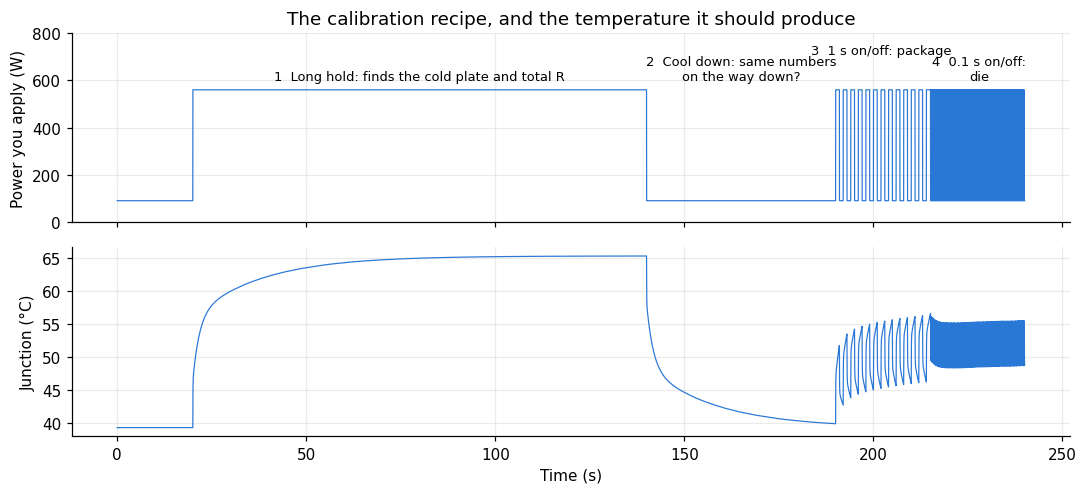

In [4]:
t, p = recipe(RECIPES['4 minutes: step, then on/off (the recipe)'])
output = pd.read_csv(io.StringIO(run(['./predict_gpu', 0, '/dev/stdin'], text_in='\n'.join(f'{a:.3f} {b:.5f}' for a, b in zip(p, t)))))
fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
axes[0].plot(t, p, color=SLEEP, linewidth=0.8)
axes[0].set_ylabel('Power you apply (W)')
axes[0].set_title('The calibration recipe, and the temperature it should produce')
axes[1].plot(output.time_s, output.junction_C, color=SLEEP, linewidth=0.8)
axes[1].set_ylabel('Junction (°C)')
axes[1].set_xlabel('Time (s)')
for x, y, label in ((80, 590, '1  Long hold: finds the cold plate and total R'), (165, 590, '2  Cool down: same numbers\non the way down?'), (202, 700, '3  1 s on/off: package'), (228, 590, '4  0.1 s on/off:\ndie')):
    axes[0].annotate(label, (x, y), ha='center', va='bottom', fontsize=8.5)
axes[0].set_ylim(0, 800)
plt.tight_layout(); plt.savefig('calibration_recipe.png', dpi=130, bbox_inches='tight'); plt.show()

**How to read this figure.** The top shows the power to apply, the bottom the temperature that results. Each section teaches a different bucket:

1. **Long hold:** gives the slow cold plate time to fill, which sets the total R.
2. **Cool down:** checks that the same numbers work in reverse. This is also the idle that the on/off sections start from.
3. **1 s on/off:** too fast for the plate, so it shows the package.
4. **0.1 s on/off:** too fast for the package, so it shows the die.

**What the table above shows.** The 4-minute recipe's largest error anywhere is 0.4 °C, against 2.7 °C for a 3-minute single step. So the on/off sections are what matter, and they cost only 50 s. The remaining 0.2 °C probably comes from the sensor's 1 °C steps. A 1-minute run gets a warning from `fit_gpu`: it's too short for the slow cold plate.

**The recipe**, with the rest of the machine quiet so the coolant holds steady:

| Time | Load |
|---|---|
| 0–20 s | Idle |
| 20–140 s | The hardest load you have, held |
| 140–190 s | Idle |
| 190–215 s | 1 s on, 1 s off |
| 215–240 s | 0.1 s on, 0.1 s off |

Then run `./fit_gpu gpu_fit.h gpu0.txt gpu1.txt ...`. It warns if the run was too short, if power didn't vary enough, or if the error suggests the coolant moved.

**Be careful:** the recipe has only been tested on this made-up GPU, whose physics match the model exactly. A real GPU won't be so tidy. It does confirm that the recipe contains enough information to pin down all the numbers.

## Step 2: Forecast the worst case

**The idea.** Each bucket's level a few seconds from now depends on two things: what's already in the buckets, and what you pour in from now on. Because the physics is linear, those two parts simply add up:

```
junction in 5 s = coolant
                + (what's left of the die's lift) + (what's left of the package's lift) + (what's left of the plate's lift)
                + (rise per watt) x (power from now until then)
```

So one forecast takes a handful of multiplications. `gpu_forecast_start` works out the weights once, by running the model forward from each bucket alone.

**Why it's a real worst case.** More power can only make the junction hotter, so the hottest possible future is the GPU running at peak power the whole time. Under that same load the temperature only climbs, so the end of the horizon is also the hottest moment before it. Add the margin for model error, and that's the bound.

**The two boundaries:**

* **Initial condition:** how hot each layer is now, kept up to date from every power sample.
* **Boundary condition:** the coolant, from junction reading − die lift. The water takes minutes to change, so it hardly moves in a few seconds.

Everything from here on fits on the first 50 s, so the last 32 s are unseen. Here's one forecast worked by hand and checked against the C code:

In [5]:
# Everything from here on fits on the first 50 s only, so the last 32 s are unseen.
HELD_OUT = HERE / 'samples' / 'control_first_50s'
print(calibrate(HELD_OUT, {g: SAMPLES[g][SAMPLES[g].time_s < 50] for g in GPUS}))
SPLIT_S = 50.0

# Work one forecast out by hand, from GPU 0's fitted numbers.
worked = '''
#include <stdio.h>
#include "gpu_model.h"
#include "gpu_fit.h"
int main(void) {
    GpuForecast f; gpu_forecast_start(&f, &GPU_FITS[0], 5.0);
    printf("%.4f %.4f %.4f %.6f %.2f %.2f %.2f\\n", f.from_die, f.from_package, f.from_plate, f.per_watt, GPU_FITS[0].peak_power, GPU_FITS[0].idle_power, GPU_FITS[0].margin);
}
'''
with tempfile.TemporaryDirectory() as folder:
    source = Path(folder) / 'weights.c'
    source.write_text(worked)
    run(['cc', '-O2', '-Wno-unused-function', f'-I{HERE}', source, '-lm', '-o', Path(folder) / 'weights'])
    from_die, from_package, from_plate, per_watt, peak, idle, margin = map(float, run([Path(folder) / 'weights']).split())
print(f"How much of each layer's lift is left after 5 s: die {from_die:.3f}, package {from_package:.3f}, plate {from_plate:.3f}")
print(f"Junction rise after 5 s per watt held: {per_watt:.4f} °C/W. Peak power {peak:.0f} W, idle {idle:.0f} W, margin {margin:.1f} °C")

output = predict(HERE, 0, 'sensor', 'horizon=5')
now = output.iloc[(output.time_s - 20.0).abs().argmin()]
# The layers themselves aren't printed, so recover "what's already there" from the two forecast columns.
already_there = now.worst_case_C - margin - per_watt * peak
print(f"\nAt t = {now.time_s:.1f} s, GPU 0: junction {now.junction_C:.1f} °C, coolant {now.coolant_C:.1f} °C")
print(f"  with no more power at all, in 5 s it would be {already_there:.1f} °C")
print(f"  {already_there:.1f} + {per_watt:.4f} x {peak:.0f} W + {margin:.1f} margin = {already_there + per_watt * peak + margin:.1f} °C worst case (the C code says {now.worst_case_C:.1f})")

GPU 0: R 0.0156 + 0.0245 + 0.0146 = 0.0546 K/W; C 2.67, 79.6, 1087 J/K; coolant 34.4 °C; power 89 to 575 W; margin 1.6 °C
    error 0.72 °C over 4046 readings; on the last 30% when fitted only on the rest: 0.79 °C
GPU 1: R 0.0164 + 0.0180 + 0.0095 = 0.0439 K/W; C 2.06, 63.5, 1409 J/K; coolant 35.1 °C; power 93 to 574 W; margin 1.5 °C
    error 0.71 °C over 4051 readings; on the last 30% when fitted only on the rest: 0.75 °C
GPU 2: R 0.0158 + 0.0223 + 0.0155 = 0.0535 K/W; C 2.26, 73.9, 820 J/K; coolant 31.0 °C; power 91 to 574 W; margin 1.8 °C
    error 0.77 °C over 3077 readings; on the last 30% when fitted only on the rest: 0.79 °C
GPU 3: R 0.0158 + 0.0187 + 0.0070 = 0.0416 K/W; C 2.82, 66.7, 2372 J/K; coolant 30.2 °C; power 85 to 580 W; margin 1.7 °C
    error 0.78 °C over 3376 readings; on the last 30% when fitted only on the rest: 0.85 °C



How much of each layer's lift is left after 5 s: die 0.003, package 0.110, plate 0.721
Junction rise after 5 s per watt held: 0.0395 °C/W. Peak power 576 W, idle 90 W, margin 1.6 °C

At t = 20.0 s, GPU 0: junction 54.7 °C, coolant 34.2 °C
  with no more power at all, in 5 s it would be 37.0 °C
  37.0 + 0.0395 x 576 W + 1.6 margin = 61.3 °C worst case (the C code says 61.3)


**Reading those weights.** After 5 s, the die has forgotten almost everything (0.3% of its lift remains), while the plate still holds 72%. So the slow layers are the memory, and the fast die responds only to what you do next.

**Now the test against the real sensor.** At each moment, make the forecast, then look at the hottest reading in the following seconds. Does the bound hold?

In [6]:
def score_bound(folder, gpu, horizon, start=0.0):
    '''At every 20th sample, compare the worst-case forecast with the hottest the sensor really read over the next horizon seconds.'''
    output = predict(folder, gpu, 'sensor', f'horizon={horizon}')
    times, values = READINGS[gpu].time_s.to_numpy(), READINGS[gpu].junction_C.to_numpy()
    keep = output[(output.time_s >= start) & (output.time_s < times[-1] - horizon)].iloc[::20]
    t = keep.time_s.to_numpy()
    hottest = np.array([values[np.searchsorted(times, x):np.searchsorted(times, x + horizon) + 1].max() for x in t])
    gap = keep.worst_case_C.to_numpy() - hottest
    later = values[np.minimum(np.searchsorted(times, t + horizon), len(values) - 1)]
    return dict(held=np.mean(gap >= 0), miss=-gap.min(), slack=gap.mean(), likely=rms(keep.junction_if_held_C.to_numpy() - later), unchanged=rms(keep.junction_C.to_numpy() - later))

rows, likely_rows = [], []
for horizon in (1, 2, 5, 10):
    for label, folder, start in (('whole 82 s (fit on all of it)', HERE, 0.0), ('last 32 s (fit never saw it)', HELD_OUT, SPLIT_S)):
        scores = [score_bound(folder, g, horizon, start) for g in GPUS]
        rows.append({'horizon': f'{horizon} s', 'part of the run': label, 'bound held (worst GPU)': f"{100 * min(s['held'] for s in scores):.1f}%", 'largest miss': f"{max(max(s['miss'] for s in scores), 0):.2f} °C", 'how far above reality, on average': f"{np.mean([s['slack'] for s in scores]):.1f} °C"})
        if start: likely_rows.append({'horizon': f'{horizon} s', 'assume recent power continues': f"{np.mean([s['likely'] for s in scores]):.2f} °C", 'assume the temperature stays the same': f"{np.mean([s['unchanged'] for s in scores]):.2f} °C"})
display(pd.DataFrame(rows))
display(pd.DataFrame(likely_rows))

,horizon,part of the run,bound held (worst GPU),largest miss,"how far above reality, on average"
0,1 s,whole 82 s (fit on all of it),98.2%,0.68 °C,3.5 °C
1,1 s,last 32 s (fit never saw it),97.2%,0.08 °C,1.5 °C
2,2 s,whole 82 s (fit on all of it),97.6%,0.61 °C,3.9 °C
3,2 s,last 32 s (fit never saw it),100.0%,0.00 °C,1.4 °C
4,5 s,whole 82 s (fit on all of it),97.3%,0.46 °C,3.9 °C
5,5 s,last 32 s (fit never saw it),100.0%,0.00 °C,1.1 °C
6,10 s,whole 82 s (fit on all of it),97.7%,0.43 °C,3.4 °C
7,10 s,last 32 s (fit never saw it),100.0%,0.00 °C,0.9 °C


,horizon,assume recent power continues,assume the temperature stays the same
0,1 s,1.55 °C,1.69 °C
1,2 s,2.12 °C,2.31 °C
2,5 s,2.97 °C,3.00 °C
3,10 s,3.30 °C,3.30 °C


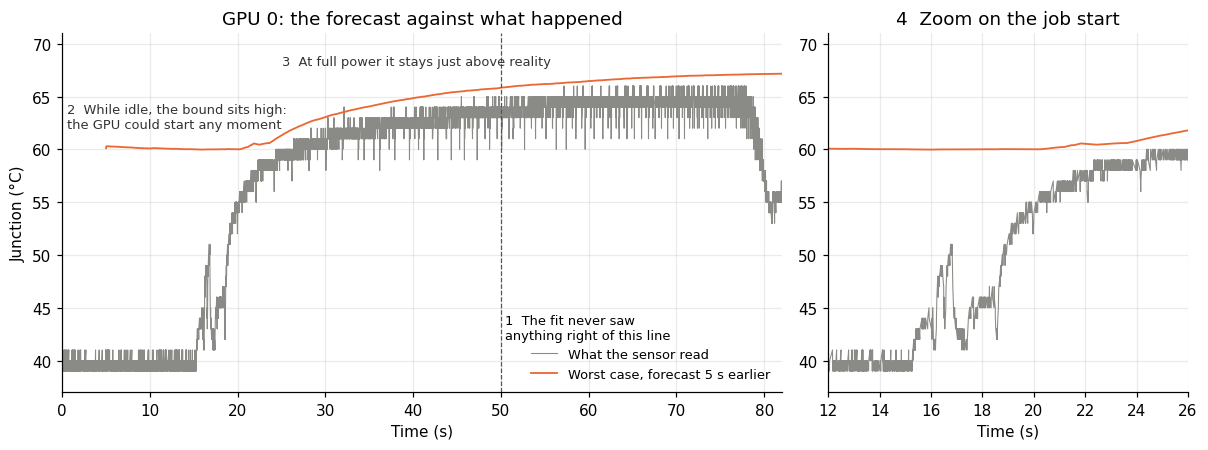

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios': [2, 1]})
HORIZON = 5
output = predict(HELD_OUT, 0, 'sensor', f'horizon={HORIZON}')
readings = READINGS[0]
for ax, (left, right) in zip(axes, ((0, 82), (12, 26))):
    ax.plot(readings.time_s, readings.junction_C, color=NONE, linewidth=0.7, label='What the sensor read')
    ax.plot(output.time_s[::10] + HORIZON, output.worst_case_C[::10], color=CAP, linewidth=1.2, label='Worst case, forecast 5 s earlier')
    ax.set_xlim(left, right); ax.set_xlabel('Time (s)')
axes[0].set_ylabel('Junction (°C)')
axes[0].axvline(SPLIT_S, color='#555', linewidth=0.8, linestyle='--')
axes[0].annotate('1  The fit never saw\nanything right of this line', (SPLIT_S + 0.5, 42), fontsize=8.5)
axes[0].annotate('2  While idle, the bound sits high:\nthe GPU could start any moment', (0.5, 62), fontsize=8.5, color='#333')
axes[0].annotate('3  At full power it stays just above reality', (25, 68), fontsize=8.5, color='#333')
for ax in axes: ax.set_ylim(37, 71)
axes[0].legend(loc='lower right', frameon=False, fontsize=8.5)
axes[0].set_title('GPU 0: the forecast against what happened')
axes[1].set_title('4  Zoom on the job start')
plt.tight_layout(); plt.savefig('forecast_vs_sensor.png', dpi=130, bbox_inches='tight'); plt.show()

**How to read this figure.** The gray line is the real sensor. The orange line is the worst case forecast 5 s earlier, shifted right so the two line up in time. If the bound works, orange stays above gray.

1. **The dashed line:** the fit never saw anything to its right.
2. **While idle, the bound sits about 20 °C high.** That's correct: the question is "what if it starts now?", and 5 s of full power really would do that.
3. **At full power it stays just above reality,** about 1 °C on the unseen part.
4. **The zoom** shows the job start, the hardest moment, with the bound still clear.

**What the first table shows.** The bound held 97–100% of the time, and the largest miss was 0.68 °C. The average gap of 3–4 °C over the whole run comes mostly from the idle stretch, and on the unseen full-power part it's about 1–1.5 °C.

**What the second table shows: a limit of forecasting.** Assuming recent power continues barely beats assuming no change at all (1.55 vs 1.69 °C at 1 s, and equal by 10 s). The model knows the physics, not the job's plans, and on this unseen stretch the job's power changes without warning. So use the **worst case** for safety decisions. Don't expect a sharp "most likely" forecast unless you also know what the workload will do next.

**Be careful:** this is one job on one node. Peak power comes from calibration, so a workload that exceeds it could exceed the bound. Calibrate with your hardest load.

## Step 3: Slow down to stay under a limit

**Turning the forecast around.** Instead of "how hot at this power?", ask "how much power leaves me at the limit?" Because the forecast is a straight line in power, that's one division:

```
allowed power = (limit − margin − where the junction would be with no more power) / (rise per watt)
```

**Two ways to get down to that power:**

* **Sleeps:** run flat out, then pause. To average 400 W from 560 W awake and 90 W asleep, sleep (560 − 400) / (560 − 90) = 34% of the time.
* **A power cap:** tell the GPU not to exceed 400 W, so it lowers its clock.

**How the test works.** `replay_gpu` replays the rocHPL trace as a fixed amount of work. Sleeping pauses the work, so it takes longer. The controller uses the numbers from the first 50 s. The simulated GPU uses the numbers from the full run, so the controller's model is slightly wrong, as it would be in real life. The controller sees the power, plus the junction only every 6.5 ms and in 1 °C steps.

**Assumptions:** asleep, the GPU draws its idle power. Under a cap, power above idle goes as speed^N (N = 2 by default). N = 1 would make a cap no better than sleeping, and clock-limited work usually falls between 2 and 3. Whether HPL does is something to measure (Step 8).

In [8]:
BUILD = HERE / 'samples' / 'control_first_50s' / 'replay_gpu'
run(['cc', '-O2', '-Wno-unused-function', '-DCONTROLLER_FIT="samples/control_first_50s/gpu_fit.h"', 'replay_gpu.c', '-lm', '-o', BUILD])

_cache = {}
def replay(gpu, trace=None, keep_trace=False, **options):
    '''Run replay_gpu. Returns its score, and with keep_trace the full temperature trace too.'''
    key = (gpu, trace, keep_trace, tuple(sorted(options.items())))
    if key in _cache: return _cache[key]
    with tempfile.TemporaryDirectory() as folder:
        path = Path(folder) / 'run.csv'
        words = run([BUILD, gpu, trace or f'samples/gpu{gpu}.txt', f'csv={path}'] + [f'{k}={v}' for k, v in options.items()]).split()
        steps = pd.read_csv(path)
    t, j = steps.time_s.to_numpy(), steps.junction_C.to_numpy()
    score = dict(work=float(words[0]), took=float(words[1]), energy=float(words[2]), peak=j.max(), std=time_std(t, j),
                 q2=fatigue(j, 2), q4=fatigue(j, 4), q6=fatigue(j, 6), q2_big=fatigue(j, 2, 2.0))
    if keep_trace: score['trace'] = steps
    _cache[key] = score
    return score

def versus_none(gpu, trace=None, **options):
    '''Compare a policy with running flat out, on the same work.'''
    base = replay(gpu, trace, **{k: v for k, v in options.items() if k in ('group', 'jump', 'jump_at')})
    test = replay(gpu, trace, **options)
    return dict(slower=100 * (test['took'] / base['took'] - 1), peak_before=base['peak'], peak=test['peak'], std_before=base['std'], std=test['std'],
                q2=test['q2'] / base['q2'], q4=test['q4'] / base['q4'], q6=test['q6'] / base['q6'], q2_big=test['q2_big'] / base['q2_big'], energy=100 * (test['energy'] / base['energy'] - 1))

def table_row(label, scores):
    m = pd.DataFrame(scores).mean()
    return {'test': label, 'runtime': f'{m.slower:+.1f}%', 'peak': f'{m.peak_before:.1f} → {m.peak:.1f} °C', 'spread (std)': f'{m.std_before:.1f} → {m["std"]:.1f} °C',
            'fatigue, q=2': f'x{m.q2:.2f}', 'q=2, swings ≥ 2 °C': f'x{m.q2_big:.2f}', 'q=4': f'x{m.q4:.2f}', 'q=6': f'x{m.q6:.2f}', 'energy': f'{m.energy:+.1f}%'}

check = replay(0)
direct = predict(HERE, 0)
print(f"Sanity check, GPU 0 with no control: peak {check['peak']:.1f} °C here vs {direct.junction_C.max():.1f} °C from predict_gpu (different fit), {check['took']:.1f} s of work in {check['work']:.1f} s")

Sanity check, GPU 0 with no control: peak 65.1 °C here vs 65.1 °C from predict_gpu (different fit), 82.2 s of work in 82.2 s


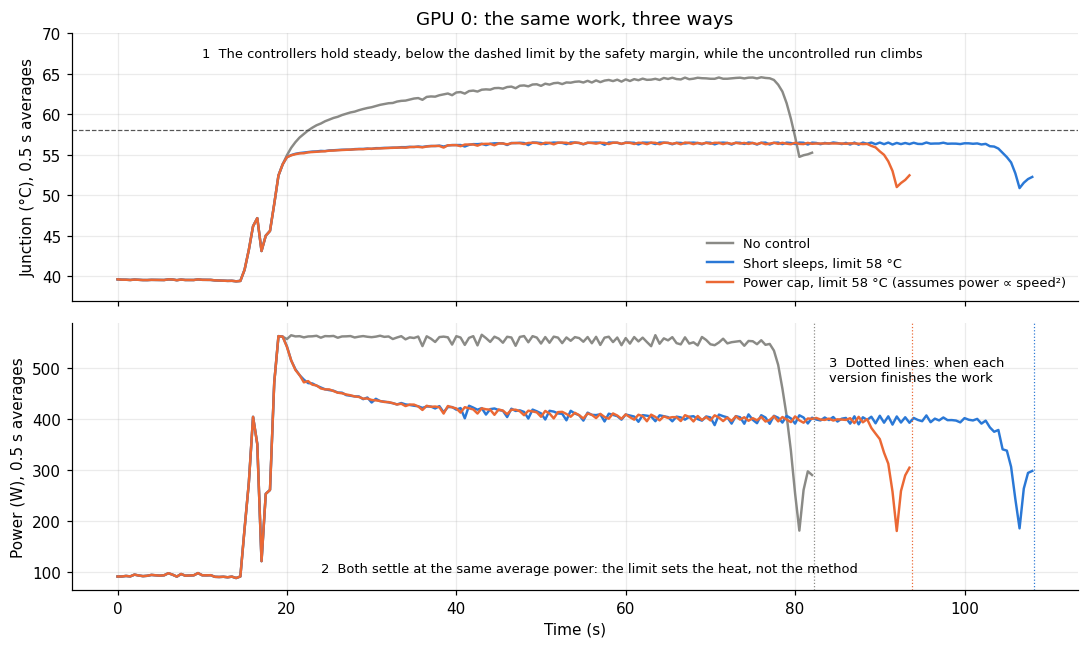

{'none': np.float64(82.2), 'sleep': np.float64(108.2), 'cap': np.float64(93.8)}


In [9]:
GPU, LIMIT = 0, 58
none = replay(GPU, keep_trace=True)['trace']
slept = replay(GPU, keep_trace=True, policy='forecast', limit=LIMIT, horizon=5, period=0.001)['trace']
capped = replay(GPU, keep_trace=True, policy='cap', limit=LIMIT, horizon=5, period=0.001, speed_power=2)['trace']

def half_seconds(steps, column):
    weight = pd.Series(np.diff(steps.time_s, prepend=steps.time_s.iloc[0]), index=steps.index)
    bins = (steps.time_s // 0.5).astype(int)
    return bins.drop_duplicates().to_numpy() * 0.5, (steps[column] * weight).groupby(bins).sum().to_numpy() / weight.groupby(bins).sum().to_numpy()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for steps, color, label in ((none, NONE, 'No control'), (slept, SLEEP, f'Short sleeps, limit {LIMIT} °C'), (capped, CAP, f'Power cap, limit {LIMIT} °C (assumes power ∝ speed²)')):
    axes[0].plot(*half_seconds(steps, 'junction_C'), color=color, label=label)
    axes[1].plot(*half_seconds(steps, 'power_W'), color=color)
axes[0].axhline(LIMIT, color='#555', linewidth=0.8, linestyle='--')
axes[0].set_ylabel('Junction (°C), 0.5 s averages'); axes[1].set_ylabel('Power (W), 0.5 s averages'); axes[1].set_xlabel('Time (s)')
axes[0].legend(frameon=False, fontsize=8.5, loc='lower right')
axes[0].set_title('GPU 0: the same work, three ways')
axes[0].set_ylim(37, 70)
axes[0].annotate('1  The controllers hold steady, below the dashed limit by the safety margin, while the uncontrolled run climbs', (10, 67), fontsize=8.5)
axes[1].annotate('2  Both settle at the same average power: the limit sets the heat, not the method', (24, 100), fontsize=8.5)
for steps, color in ((none, NONE), (slept, SLEEP), (capped, CAP)):
    axes[1].axvline(steps.time_s.iloc[-1], color=color, linewidth=0.8, linestyle=':')
axes[1].annotate('3  Dotted lines: when each\nversion finishes the work', (84, 475), fontsize=8.5)
plt.tight_layout(); plt.savefig('replay_with_sleeps.png', dpi=130, bbox_inches='tight'); plt.show()
print({name: round(steps.time_s.iloc[-1], 1) for name, steps in (('none', none), ('sleep', slept), ('cap', capped))})

**How to read this figure.**

1. **Top:** without control, the junction climbs to about 65 °C. Both controllers flatten it near 56.5 °C. They sit below the 58 °C dashed line because the limit is deliberately held back by the 1.6 °C margin.
2. **Bottom:** after an initial burst to full power, both settle at the same average power, about 400 W. The limit sets the heat, however you get there.
3. **Dotted lines:** when each run finishes the same work. Without control it takes 82 s, with the cap 94 s, and with sleeps 108 s.

**Notice the cap's advantage.** Both remove the same heat, but the cap finishes much sooner. Under the assumption here, lowering the clock takes less energy per unit of work, whereas sleeping just pauses. Step 8 says how to check that assumption.

## Step 4: What does steadiness cost?

**Scoring fatigue.** The standard tools are:

* **Rainflow counting** finds each heat-up/cool-down cycle in a temperature trace, including small cycles nested inside big ones. Think of counting each bend of the paperclip and how far it went.
* **Coffin-Manson** says each cycle's damage grows as (swing)^q. With q = 4, a 20 °C swing does 16 times the damage of a 10 °C swing.

Nobody knows q for this chip, since it depends on what fails first. Published values for solder are around 2–2.5, and other materials can be higher, so this notebook shows q = 2, 4 and 6. Each result is a **ratio to the same work with no control** (x0.5 = half the fatigue). It's not a lifetime in years.

**The test.** Lower each GPU's limit 2–12 °C below its uncontrolled peak, and compare four ways of holding that limit. Results are averaged over the 4 GPUs. "Sensor-only" is a simple baseline with no model: sleep whenever the sensor reads at or above the limit.

,test,runtime,peak,spread (std),"fatigue, q=2","q=2, swings ≥ 2 °C",q=4,q=6,energy
0,"Short sleeps (forecast), limit 2 °C under the ...",+4.2%,61.9 → 60.5 °C,8.5 → 7.9 °C,x0.97,x0.95,x0.82,x0.73,+0.9%
1,"Short sleeps (forecast), limit 4 °C under the ...",+10.7%,61.9 → 59.0 °C,8.5 → 7.2 °C,x0.95,x0.89,x0.66,x0.53,+2.2%
2,"Short sleeps (forecast), limit 6 °C under the ...",+20.7%,61.9 → 57.1 °C,8.5 → 6.3 °C,x0.92,x0.81,x0.48,x0.33,+4.2%
3,"Short sleeps (forecast), limit 8 °C under the ...",+34.2%,61.9 → 55.3 °C,8.5 → 5.4 °C,x0.90,x0.72,x0.35,x0.20,+7.0%
4,"Short sleeps (forecast), limit 10 °C under the...",+52.5%,61.9 → 53.7 °C,8.5 → 4.5 °C,x0.89,x0.64,x0.25,x0.11,+10.7%
5,"Short sleeps (forecast), limit 12 °C under the...",+79.0%,61.9 → 51.9 °C,8.5 → 3.6 °C,x0.87,x0.55,x0.17,x0.06,+16.1%
6,"Sensor-only sleeps (no model), limit 2 °C unde...",+2.1%,61.9 → 61.1 °C,8.5 → 8.2 °C,x1.18,x0.99,x0.91,x0.84,+0.4%
7,"Sensor-only sleeps (no model), limit 4 °C unde...",+6.5%,61.9 → 59.7 °C,8.5 → 7.7 °C,x1.48,x0.92,x0.73,x0.60,+1.3%
8,"Sensor-only sleeps (no model), limit 6 °C unde...",+14.3%,61.9 → 58.6 °C,8.5 → 6.9 °C,x2.00,x0.89,x0.62,x0.46,+2.9%
9,"Sensor-only sleeps (no model), limit 8 °C unde...",+25.0%,61.9 → 56.3 °C,8.5 → 6.0 °C,x2.52,x0.81,x0.43,x0.25,+5.1%


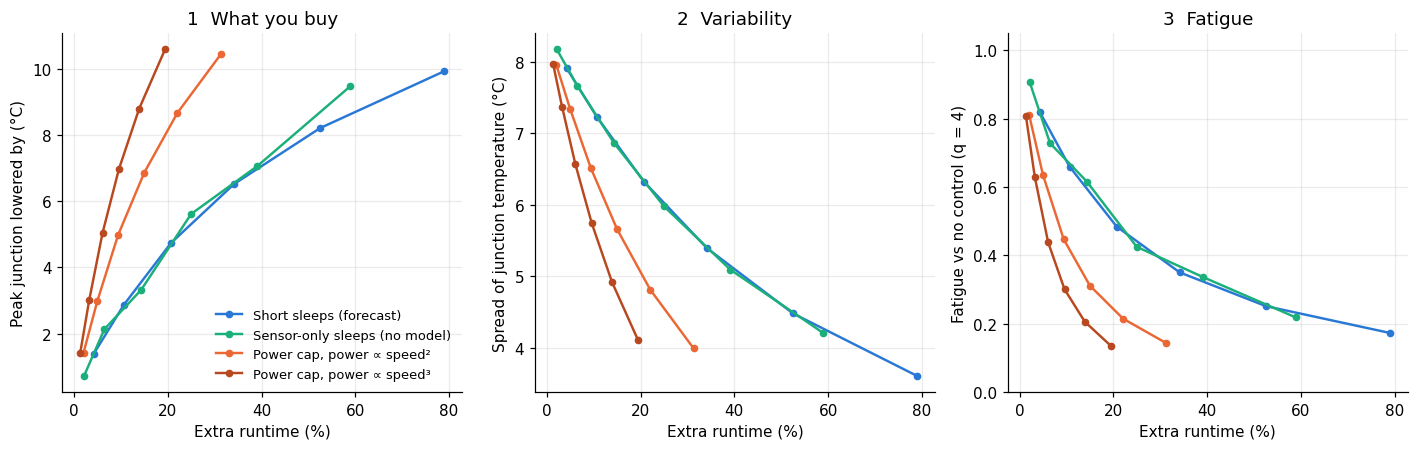

In [10]:
PEAKS = {g: replay(g)['peak'] for g in GPUS}
DROPS = (2, 4, 6, 8, 10, 12)
POLICIES = {
    'Short sleeps (forecast)': dict(policy='forecast', color=SLEEP),
    'Sensor-only sleeps (no model)': dict(policy='reactive', color=REACTIVE),
    'Power cap, power ∝ speed²': dict(policy='cap', speed_power=2, color=CAP),
    'Power cap, power ∝ speed³': dict(policy='cap', speed_power=3, color='#b8481f'),
}
curves, rows = {}, []
for name, settings in POLICIES.items():
    options = {k: v for k, v in settings.items() if k != 'color'}
    curves[name] = []
    for drop in DROPS:
        scores = [versus_none(g, limit=PEAKS[g] - drop, horizon=5, period=0.001, **options) for g in GPUS]
        curves[name].append(pd.DataFrame(scores).mean())
        rows.append(table_row(f'{name}, limit {drop} °C under the peak', scores))
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True)
for name, settings in POLICIES.items():
    curve = pd.DataFrame(curves[name])
    style = dict(color=settings['color'], marker='o', markersize=4, label=name)
    axes[0].plot(curve.slower, curve.peak_before - curve.peak, **style)
    axes[1].plot(curve.slower, curve['std'], **style)
    axes[2].plot(curve.slower, curve.q4, **style)
axes[0].set_ylabel('Peak junction lowered by (°C)'); axes[1].set_ylabel('Spread of junction temperature (°C)'); axes[2].set_ylabel('Fatigue vs no control (q = 4)')
axes[2].set_ylim(0, 1.05)
for ax in axes: ax.set_xlabel('Extra runtime (%)')
axes[0].legend(frameon=False, fontsize=8.5)
axes[0].set_title('1  What you buy'); axes[1].set_title('2  Variability'); axes[2].set_title('3  Fatigue')
plt.tight_layout(); plt.savefig('cost_of_cooling.png', dpi=130, bbox_inches='tight'); plt.show()

**How to read this figure.** Every point is one limit, and further right means more runtime paid. The best method gets the most benefit furthest left.

1. **Peak lowered:** up and left is better.
2. **Spread of temperature** (standard deviation over the run): down and left is better.
3. **Fatigue at q = 4:** down and left is better.

**What it shows:**

* **A cap beats sleeping, if N is 2 or more.** For a limit 6 °C under the peak, sleeps cost +21% runtime and +4% energy, while a cap at N = 2 costs +9% runtime and *saves* 6% energy. Both give about half the fatigue at q = 4 (x0.48 and x0.45).
* **Sleeps raise energy** because the GPU keeps drawing idle power for the extra time.
* **The forecast doesn't beat the sensor at holding a peak here.** Blue and green lie almost on top of each other. When you can act every millisecond, you can simply react. The forecast's gain at this speed is avoiding chatter: at q = 2 the sensor-only policy *raises* fatigue (x2.0 against x0.92) by flicking on and off around each 1 °C sensor step.
* **This trace is one huge cycle.** It goes from idle to full power and back, about 25 °C, and that dominates both the spread and the fatigue. A limit shrinks that swing from the top, and sleeping can't raise the bottom. So the benefit grows steadily with how much runtime you give up, with no sudden sweet spot.

## Step 5: How long can a sleep be?

**Why this matters.** The die is a tiny bucket: it responds in about 30 ms. Sleep much shorter than that and it can't drain, so it only feels the average power. Sleep longer and it follows you down and back up, so **each sleep becomes a thermal cycle of its own.** That's the very thing you're trying to prevent.

Same limit (6 °C under the peak), same average power, and the only change is how often the controller acts. Each period sleeps first, then works.

,test,runtime,peak,spread (std),"fatigue, q=2","q=2, swings ≥ 2 °C",q=4,q=6,energy
0,"Forecast, one decision every 1 ms",+20.7%,61.9 → 57.1 °C,8.5 → 6.3 °C,x0.92,x0.81,x0.48,x0.33,+4.2%
1,"Forecast, one decision every 2 ms",+20.7%,61.9 → 57.1 °C,8.5 → 6.3 °C,x0.99,x0.81,x0.48,x0.32,+4.2%
2,"Forecast, one decision every 5 ms",+20.7%,61.9 → 57.2 °C,8.5 → 6.3 °C,x1.18,x0.83,x0.50,x0.33,+4.2%
3,"Forecast, one decision every 10 ms",+20.7%,61.9 → 57.2 °C,8.5 → 6.3 °C,x1.48,x0.86,x0.51,x0.34,+4.2%
4,"Forecast, one decision every 20 ms",+20.8%,61.9 → 57.3 °C,8.5 → 6.3 °C,x2.08,x0.92,x0.54,x0.34,+4.3%
5,"Forecast, one decision every 50 ms",+20.8%,61.9 → 57.8 °C,8.5 → 6.4 °C,x3.75,x3.78,x0.78,x0.38,+4.2%
6,"Forecast, one decision every 100 ms",+20.8%,61.9 → 58.1 °C,8.5 → 6.4 °C,x5.70,x7.76,x1.61,x0.47,+4.3%
7,"Forecast, one decision every 200 ms",+20.9%,61.9 → 58.4 °C,8.5 → 6.5 °C,x6.75,x9.27,x3.22,x0.80,+4.3%
8,"Forecast, one decision every 500 ms",+20.9%,61.9 → 58.4 °C,8.5 → 6.7 °C,x5.00,x6.81,x3.28,x0.95,+4.3%
9,"Forecast, one decision every 1000 ms",+21.1%,61.9 → 58.9 °C,8.5 → 6.8 °C,x3.44,x4.56,x2.62,x0.94,+4.3%


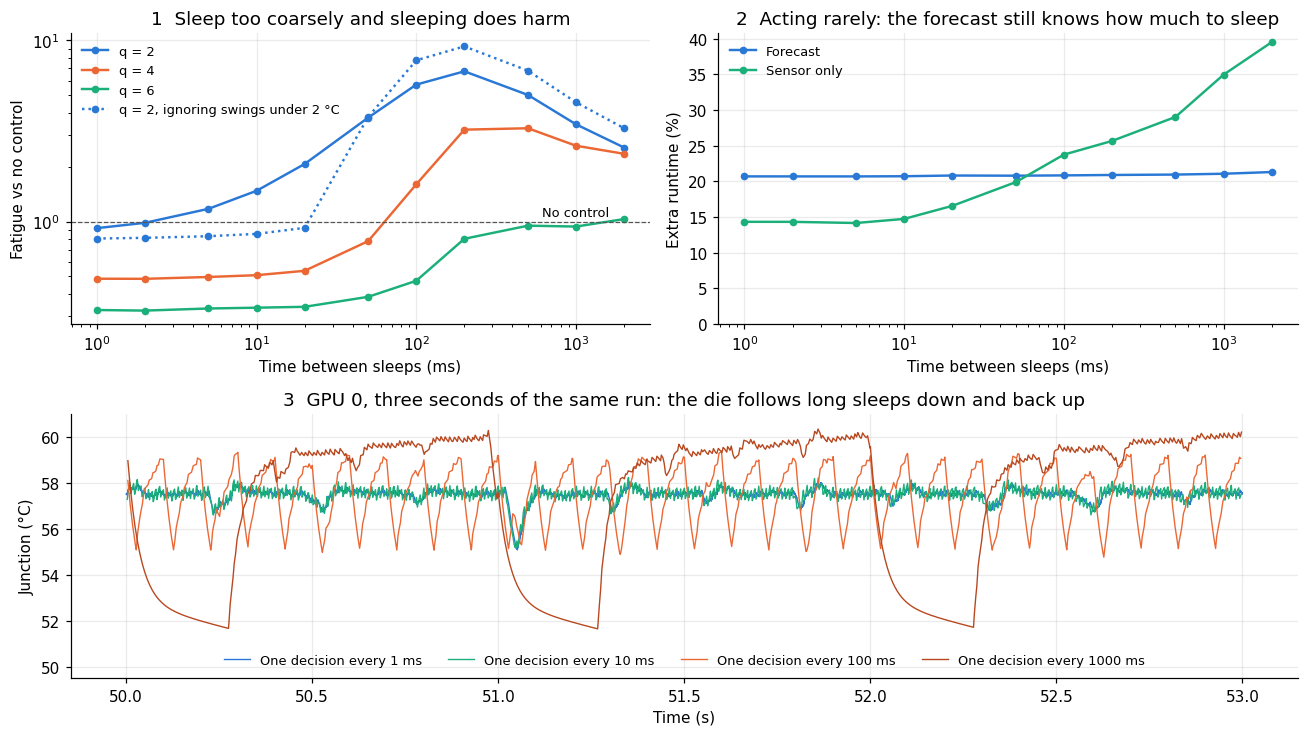

In [11]:
PERIODS = (0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0)
DROP = 6
by_period = {}
rows = []
for name, policy in (('Forecast', 'forecast'), ('Sensor only', 'reactive')):
    by_period[name] = []
    for period in PERIODS:
        scores = [versus_none(g, limit=PEAKS[g] - DROP, horizon=5, period=period, policy=policy) for g in GPUS]
        by_period[name].append(pd.DataFrame(scores).mean())
        rows.append(table_row(f'{name}, one decision every {period * 1000:g} ms', scores))
display(pd.DataFrame(rows))

fig = plt.figure(figsize=(12, 6.8))
grid = fig.add_gridspec(2, 2, height_ratios=[1.1, 1])
fatigue_axis = fig.add_subplot(grid[0, 0]); cost_axis = fig.add_subplot(grid[0, 1]); ripple_axis = fig.add_subplot(grid[1, :])
curve = pd.DataFrame(by_period['Forecast'])
ms = np.array(PERIODS) * 1000
for column, label, color in (('q2', 'q = 2', SLEEP), ('q4', 'q = 4', CAP), ('q6', 'q = 6', REACTIVE)):
    fatigue_axis.plot(ms, curve[column], marker='o', markersize=4, color=color, label=label)
fatigue_axis.plot(ms, curve.q2_big, marker='o', markersize=4, color=SLEEP, linestyle=':', label='q = 2, ignoring swings under 2 °C')
fatigue_axis.axhline(1, color='#555', linewidth=0.8, linestyle='--')
fatigue_axis.annotate('No control', (1000, 1.08), fontsize=8.5, ha='center')
fatigue_axis.set_xscale('log'); fatigue_axis.set_yscale('log')
fatigue_axis.set_xlabel('Time between sleeps (ms)'); fatigue_axis.set_ylabel('Fatigue vs no control')
fatigue_axis.set_title('1  Sleep too coarsely and sleeping does harm'); fatigue_axis.legend(frameon=False, fontsize=8.5)
cost_axis.plot(ms, curve.slower, marker='o', markersize=4, color=SLEEP, label='Forecast')
cost_axis.plot(ms, pd.DataFrame(by_period['Sensor only']).slower, marker='o', markersize=4, color=REACTIVE, label='Sensor only')
cost_axis.set_xscale('log'); cost_axis.set_ylim(bottom=0)
cost_axis.set_xlabel('Time between sleeps (ms)'); cost_axis.set_ylabel('Extra runtime (%)')
cost_axis.set_title('2  Acting rarely: the forecast still knows how much to sleep'); cost_axis.legend(frameon=False, fontsize=8.5)
limit = PEAKS[0] - DROP
for period, color in ((0.001, SLEEP), (0.01, REACTIVE), (0.1, CAP), (1.0, '#b8481f')):
    steps = replay(0, keep_trace=True, limit=limit, horizon=5, period=period, policy='forecast')['trace']
    window = steps[(steps.time_s > 50) & (steps.time_s < 53)]
    ripple_axis.plot(window.time_s, window.junction_C, color=color, linewidth=0.9, label=f'One decision every {period * 1000:g} ms')
ripple_axis.set_xlabel('Time (s)'); ripple_axis.set_ylabel('Junction (°C)')
ripple_axis.set_title('3  GPU 0, three seconds of the same run: the die follows long sleeps down and back up')
ripple_axis.set_ylim(49.5, 61)
ripple_axis.legend(frameon=False, fontsize=8.5, ncol=4, loc='lower center')
plt.tight_layout(); plt.savefig('sleep_length.png', dpi=130, bbox_inches='tight'); plt.show()

**How to read this figure.**

1. **Top left: fatigue against time between sleeps** (both axes logarithmic, dashed line = no control). Below the line the control helps, and above it the control hurts. Up to about 20 ms, q = 4 and q = 6 hold steady. By 100 ms, q = 4 has crossed the line, and at 200 ms it's over 3 times worse than doing nothing. q = 6 stays below the line until about 2 s, because it counts mainly the big job-level swing. q = 2, which counts every tiny swing, crosses the line much earlier, at about 5 ms.
2. **Top right: runtime.** The forecast's cost stays at 21% however rarely it acts, while the sensor-only policy's grows from 14% to 40%. It has no idea how much sleep is needed, so it overshoots.
3. **Bottom: why.** These are three seconds of the same GPU. At 1 and 10 ms the junction is nearly flat around 57.5 °C. At 100 ms it saws up and down 4 °C. At 1 s it swings 8 °C, every second.

**The dotted line** ignores swings under 2 °C, in case tiny cycles do no real harm. That's a real possibility, because small enough strains may not cause fatigue at all. With that rule, q = 2 only turns harmful between 20 and 50 ms, in line with q = 4. So how much harm a 5–20 ms sleep does depends on whether those tiny swings count, while longer sleeps look harmful either way.

**The rule: keep the work-plus-sleep period to 20 ms or less, and shorter if you can**, so at a third asleep each sleep is under about 7 ms. Longer pauses cause harm even though the average temperature looks fine, and an average-temperature monitor would never show it.

**Be careful:** the die's response comes from power telemetry every 3.3 ms, so behaviour below about 10 ms is at the edge of what this data can show. And each real sleep has wake-up costs, which this ignores.

**So can you act rarely without the damage?** A power cap has no sleep-and-wake ripple, so the forecast should finally pay off there. The next table updates the cap at different rates, with different forecast horizons. The limit is again 6 °C under the peak, and N = 2.

In [12]:
rows = []
for period in (0.001, 0.1, 1, 2, 5, 10):
    for horizon in (1, 2, 5, 10, 20):
        if horizon < period: continue
        scores = [versus_none(g, limit=PEAKS[g] - DROP, horizon=horizon, period=period, policy='cap', speed_power=2) for g in GPUS]
        over = np.mean([replay(g, limit=PEAKS[g] - DROP, horizon=horizon, period=period, policy='cap', speed_power=2)['peak'] - (PEAKS[g] - DROP) for g in GPUS])
        m = pd.DataFrame(scores).mean()
        rows.append({'cap updated every': f'{period * 1000:g} ms' if period < 1 else f'{period} s', 'forecast horizon': f'{horizon} s', 'runtime': f'{m.slower:+.1f}%', 'peak above the limit': f'{over:+.1f} °C', 'fatigue, q=4': f'x{m.q4:.2f}', 'q=2, swings ≥ 2 °C': f'x{m.q2_big:.2f}', 'energy': f'{m.energy:+.1f}%'})
pd.DataFrame(rows)

,cap updated every,forecast horizon,runtime,peak above the limit,"fatigue, q=4","q=2, swings ≥ 2 °C",energy
0,1 ms,1 s,+9.0%,+1.2 °C,x0.46,x0.74,-6.1%
1,1 ms,2 s,+9.0%,+1.2 °C,x0.46,x0.74,-6.2%
2,1 ms,5 s,+9.4%,+1.0 °C,x0.45,x0.73,-6.4%
3,1 ms,10 s,+9.7%,+0.9 °C,x0.44,x0.72,-6.6%
4,1 ms,20 s,+10.3%,+0.7 °C,x0.43,x0.72,-7.0%
5,100 ms,1 s,+9.0%,+1.3 °C,x0.47,x0.75,-6.1%
6,100 ms,2 s,+9.1%,+1.2 °C,x0.46,x0.74,-6.2%
7,100 ms,5 s,+9.4%,+1.1 °C,x0.45,x0.74,-6.4%
8,100 ms,10 s,+9.8%,+0.9 °C,x0.44,x0.73,-6.6%
9,100 ms,20 s,+10.3%,+0.8 °C,x0.43,x0.72,-6.9%


**What this table shows: your original idea works.**

* **A cap updated every 1–5 s performs almost as well as one updated every millisecond:** about +9% runtime and x0.46–0.51 fatigue at q = 4. So no millisecond control loop is needed.
* **The peak rises slowly as updates get rarer:** about 1 °C over the limit at millisecond updates, about 1.3 °C at every 1–2 s, and about 1.9 °C at every 5 s with a 5 s forecast.
* **A longer horizon buys safety for a little runtime.** At 5 s updates, a 20 s horizon cuts the overshoot from 1.9 to 1.2 °C, for +10.2% rather than +9.3% runtime.

**A good default: update the cap every 1–2 s using a 5 s forecast.** It overshoots a little even with the margin, most likely because the 1 ms power spikes in the trace push the die up briefly, so set your limit 1–2 °C below what you really want.

## Step 6: Try to break it

So far the coolant has stayed put, and the workload has been one HPL run. These tests change that, with short sleeps at 1 ms unless the row says otherwise:

* **The coolant is warmer than during calibration,** or jumps by 3 °C mid-run. Neither is known to the controller, which only has its junction sensor to go on.
* **Cycling workloads:** square waves between 90 and 560 W, at various speeds, with a limit of 52 °C.
* **The long 3-cabinet run:** 1622 s of one average GPU's power from cabinet 1, with the whole group warming the water.

In [13]:
rows = []
DROP = 6
sets = lambda **k: [versus_none(g, limit=PEAKS[g] - DROP, horizon=5, period=0.001, **k) for g in GPUS]
rows.append(table_row('Normal run, forecast', sets(policy='forecast')))
rows.append(table_row('Coolant +3 °C from the start, unknown to the fit', sets(policy='forecast', jump=3, jump_at=0)))
rows.append(table_row('Coolant jumps +3 °C halfway, forecast', sets(policy='forecast', jump=3)))
rows.append(table_row('Coolant jumps +3 °C halfway, sensor only', sets(policy='reactive', jump=3)))
display(pd.DataFrame(rows))

# Cycling workloads: square waves of power, starting from idle
rows = []
folder = tempfile.mkdtemp()
t = np.arange(0, 240, 0.003)
for half in (20, 5, 1, 0.1):
    trace = f'{folder}/square_{half}.txt'
    wave = np.where((t + half) % (2 * half) < half, IDLE, FULL)
    wave[t < 2] = IDLE
    np.savetxt(trace, np.c_[wave, t, np.full(len(t), np.nan)], fmt='%.2f %.4f %.0f')
    for name, policy in (('forecast sleeps', dict(policy='forecast')), ('sensor-only sleeps', dict(policy='reactive')), ('power cap, speed²', dict(policy='cap'))):
        rows.append(table_row(f'{half:g} s on, {half:g} s off: {name}', [versus_none(g, trace, limit=52, horizon=5, period=0.001, **policy) for g in (0, 2)]))
display(pd.DataFrame(rows))

# The long 3-cabinet run: one average GPU's power, with the whole group warming the water
recon = pd.read_csv(HERE.parent / 'cabinet_power_recon_gpu_energy_1ms.csv', usecols=['t_since_job_start_s', 'C1_gpu_energy_W'])
trace = f'{folder}/cabinet.txt'
np.savetxt(trace, np.c_[recon.C1_gpu_energy_W.to_numpy() / 128 / 4, recon.t_since_job_start_s.to_numpy() - recon.t_since_job_start_s.iloc[0], np.full(len(recon), np.nan)], fmt='%.3f %.3f %.0f')
print(f"Cabinet 1, one average GPU, {recon.t_since_job_start_s.iloc[-1] - recon.t_since_job_start_s.iloc[0]:.0f} s")
rows = []
for limit_C in (58, 54, 50):
    for name, policy in (('forecast sleeps', dict(policy='forecast')), ('sensor-only sleeps', dict(policy='reactive')), ('power cap, speed²', dict(policy='cap'))):
        rows.append(table_row(f'Limit {limit_C} °C: {name}', [versus_none(0, trace, group=1, limit=limit_C, horizon=5, period=0.001, **policy)]))
display(pd.DataFrame(rows))
shutil.rmtree(folder)

,test,runtime,peak,spread (std),"fatigue, q=2","q=2, swings ≥ 2 °C",q=4,q=6,energy
0,"Normal run, forecast",+20.7%,61.9 → 57.1 °C,8.5 → 6.3 °C,x0.92,x0.81,x0.48,x0.33,+4.2%
1,"Coolant +3 °C from the start, unknown to the fit",+42.6%,64.9 → 57.5 °C,8.5 → 4.9 °C,x0.90,x0.68,x0.30,x0.15,+8.7%
2,"Coolant jumps +3 °C halfway, forecast",+34.7%,64.9 → 58.6 °C,9.5 → 6.3 °C,x0.89,x0.72,x0.39,x0.23,+7.1%
3,"Coolant jumps +3 °C halfway, sensor only",+27.1%,64.9 → 59.2 °C,9.5 → 6.7 °C,x2.38,x0.73,x0.42,x0.26,+5.5%


,test,runtime,peak,spread (std),"fatigue, q=2","q=2, swings ≥ 2 °C",q=4,q=6,energy
0,"20 s on, 20 s off: forecast sleeps",+41.9%,61.2 → 50.8 °C,8.4 → 4.7 °C,x0.62,x0.31,x0.10,x0.03,+11.8%
1,"20 s on, 20 s off: sensor-only sleeps",+32.9%,61.2 → 52.2 °C,8.4 → 5.2 °C,x4.71,x0.39,x0.17,x0.07,+9.3%
2,"20 s on, 20 s off: power cap, speed²",+16.8%,61.2 → 50.7 °C,8.4 → 4.9 °C,x0.31,x0.31,x0.10,x0.03,-12.7%
3,"5 s on, 5 s off: forecast sleeps",+31.8%,59.0 → 51.9 °C,6.3 → 4.3 °C,x0.53,x0.44,x0.20,x0.09,+9.0%
4,"5 s on, 5 s off: sensor-only sleeps",+25.5%,59.0 → 52.1 °C,6.3 → 4.4 °C,x1.91,x0.46,x0.23,x0.11,+7.2%
5,"5 s on, 5 s off: power cap, speed²",+13.2%,59.0 → 51.8 °C,6.3 → 4.4 °C,x0.44,x0.44,x0.20,x0.09,-9.4%
6,"1 s on, 1 s off: forecast sleeps",+12.5%,55.5 → 52.8 °C,3.8 → 3.4 °C,x0.74,x0.73,x0.54,x0.40,+3.5%
7,"1 s on, 1 s off: sensor-only sleeps",+16.5%,55.5 → 52.0 °C,3.8 → 3.0 °C,x1.16,x0.63,x0.44,x0.31,+4.6%
8,"1 s on, 1 s off: power cap, speed²",+5.6%,55.5 → 52.8 °C,3.8 → 3.4 °C,x0.72,x0.72,x0.53,x0.39,-2.9%
9,"0.1 s on, 0.1 s off: forecast sleeps",+7.4%,53.7 → 52.5 °C,2.8 → 2.6 °C,x0.89,x0.89,x0.81,x0.74,+2.1%


Cabinet 1, one average GPU, 1622 s


,test,runtime,peak,spread (std),"fatigue, q=2","q=2, swings ≥ 2 °C",q=4,q=6,energy
0,Limit 58 °C: forecast sleeps,+9.5%,64.7 → 58.8 °C,5.6 → 4.4 °C,x0.90,x0.88,x0.72,x0.33,+2.2%
1,Limit 58 °C: sensor-only sleeps,+10.3%,64.7 → 58.2 °C,5.6 → 4.3 °C,x0.96,x0.85,x0.64,x0.27,+2.4%
2,"Limit 58 °C: power cap, speed²",+4.7%,64.7 → 58.7 °C,5.6 → 4.4 °C,x0.86,x0.85,x0.67,x0.31,-2.8%
3,Limit 54 °C: forecast sleeps,+34.9%,64.7 → 54.5 °C,5.6 → 2.9 °C,x0.72,x0.68,x0.41,x0.11,+8.1%
4,Limit 54 °C: sensor-only sleeps,+31.1%,64.7 → 54.5 °C,5.6 → 2.9 °C,x0.81,x0.56,x0.29,x0.08,+7.2%
5,"Limit 54 °C: power cap, speed²",+15.9%,64.7 → 54.5 °C,5.6 → 3.1 °C,x0.62,x0.61,x0.32,x0.09,-7.8%
6,Limit 50 °C: forecast sleeps,+85.9%,64.7 → 50.4 °C,5.6 → 1.7 °C,x0.52,x0.46,x0.18,x0.03,+20.0%
7,Limit 50 °C: sensor-only sleeps,+71.7%,64.7 → 50.7 °C,5.6 → 1.7 °C,x0.81,x0.33,x0.12,x0.02,+16.7%
8,"Limit 50 °C: power cap, speed²",+36.0%,64.7 → 50.2 °C,5.6 → 1.8 °C,x0.38,x0.36,x0.11,x0.02,-13.2%


**What the first table shows: coolant changes.** "Before" here includes the jump, so the peak would have been 64.9 °C.

* **Coolant 3 °C warmer from the start:** the first junction reading corrects it, and the peak stays within 1.6 °C of the limit, which remained tied to the *old* peak. Holding that same temperature on warmer water takes much more slowing (+43%), which is correct behaviour.
* **A sudden +3 °C jump halfway:** the junction goes over the limit by about 2.7 °C on average, and no controller could prevent it, because the extra heat arrives at once. Forecast and sensor-only end at similar peaks (58.6 and 59.2 °C). A jump this sudden is itself unrealistic, since real coolant moves over tens of seconds.

**What the second table shows: cycling workloads.** The slower the cycle, the more there is to gain. On 20 s cycles, fatigue at q = 4 falls to x0.10. On 0.1 s cycles it only falls to about x0.8, because most of the fast die swing happens below the limit no matter what you do. **Slowing down can trim the top of a swing, but can't fill in the bottom.**

**What the third table shows: the long run.** The results agree with the 82 s run, including the moving coolant. A limit of 54 °C (about 10 °C under the 64.7 °C peak) costs +35% with sleeps or +16% with a cap, and cuts fatigue at q = 4 to x0.41 and x0.32. The sensor-only policy does well here too. In this table the average GPU is smoother than a real one, so it has less chatter to pay for.

## Step 7: Use it

In your Score-P tool, this is all it takes. Fill `gpu_fit.h` from calibration, then for each sample:

```c
#include "gpu_model.h"
#include "gpu_fit.h"

GpuState state;
GpuForecast forecast;
const GpuFit *fit = &GPU_FITS[gpu];
gpu_start(&state, fit, first_power_W, 0.0, first_time_s);
gpu_forecast_start(&forecast, fit, 5.0);                  /* look 5 s ahead */

/* for every sample: junction_C can be NAN when there's no reading */
GpuPrediction now = gpu_predict(&state, fit, power_W, junction_C, time_s);
double worst = gpu_worst_case(&state, fit, &forecast);    /* the metric: the hottest it could be in 5 s */

/* every 1-2 s: */
double cap_W = gpu_allowed_power(&state, fit, &forecast, limit_C);
```

Keep `cap_W` between idle power and the GPU's own limit before applying it. To sleep instead, `gpu_sleep_fraction(&state, fit, &forecast, limit_C, work_power_W)` gives the fraction of each period of 20 ms or less to spend asleep. Pass the power measured while awake as `work_power_W`, since measured power already includes earlier sleeps.

Could this keep up in real time? Timing it:

In [14]:
benchmark = '''
#include <stdio.h>
#include <time.h>
#include "gpu_model.h"
#include "gpu_fit.h"
int main(void) {
    GpuState state; GpuForecast forecast;
    const GpuFit *fit = &GPU_FITS[0];
    gpu_forecast_start(&forecast, fit, 5.0);
    gpu_start(&state, fit, 300.0, 0.0, 0.0);
    struct timespec a, b;
    double total = 0;
    int samples = 5000000;
    clock_gettime(CLOCK_MONOTONIC, &a);
    for (int i = 1; i <= samples; i++) {
        gpu_predict(&state, fit, 300.0 + (i % 7) * 40.0, (i % 2) ? NAN : 50.0, i * 0.001);
        total += gpu_worst_case(&state, fit, &forecast) + gpu_sleep_fraction(&state, fit, &forecast, 56.0, state.recent_power);
    }
    clock_gettime(CLOCK_MONOTONIC, &b);
    printf("%.0f %.3f\\n", ((b.tv_sec - a.tv_sec) * 1e9 + (b.tv_nsec - a.tv_nsec)) / samples, total / samples);
}
'''
with tempfile.TemporaryDirectory() as folder:
    source = Path(folder) / 'benchmark.c'
    source.write_text(benchmark)
    run(['cc', '-O2', '-Wno-unused-function', f'-I{HERE}', source, '-lm', '-o', Path(folder) / 'benchmark'])
    nanoseconds = float(run([Path(folder) / 'benchmark']).split()[0])
print(f"One sample (update, worst case, sleep decision) takes {nanoseconds:.0f} ns. At 1 sample per ms, that's {nanoseconds / 1e6 * 100:.4f}% of one CPU core per GPU.")

One sample (update, worst case, sleep decision) takes 29 ns. At 1 sample per ms, that's 0.0029% of one CPU core per GPU.


At 1 sample per ms, that's a negligible load, even for many GPUs.

## Step 8: What this does and doesn't show

**On real measurements:**
* The model reproduces the junction within about 0.8 °C, on data the fit never saw.
* The worst-case forecast held 97–100% of the time on the real sensor, with a largest miss of 0.7 °C.

**Only in simulation:**
* Everything about sleeping and capping. The "GPU" being controlled is this same model, with numbers from a different stretch of data. **Nothing here has controlled a real GPU.**
* The 4-minute recipe, which hasn't been run on real hardware.

**Open questions you can settle by measuring:**

| Question | Why it matters | How to measure it |
|---|---|---|
| How does runtime change with the power cap? | The cap's whole advantage rests on N. On memory-bound work, slowing the clock may cost much less time than assumed; on other work, more | Run a short HPL at 2–3 power caps, and compare times |
| What does a GPU draw during a short sleep? | The sleep numbers assume full idle power, which a GPU may not reach in milliseconds | Log power while sleeping for 5–20 ms between kernels |
| Do fast swings really do what the model says? | The die layer is at the edge of the data | Compare the sensor on a 10, 50 and 100 ms on/off load, against this model |
| Does calibration carry over? | Tested on one job and one node, on one type of GPU | Calibrate on the recipe, then score on a different job, and on another machine like Lux |

**Other limits:**
* **Fatigue numbers are ratios, not lifetimes.** q is assumed, and the sensor is one point, not the location that actually fails. It doesn't include the additional benefit of running cooler on average.
* **Peak power comes from calibration.** A harder job could beat the bound, so calibrate with your hardest load. If you know the GPU's power limit, that's an even safer value.
* **The job-level swing can't be removed this way.** Idle to full power is the biggest cycle in this trace. Slowing down shrinks it from the top, but raising the idle floor would need something else, like keeping a light load running, which wasn't tested.